# Этап 1. Вариант «категории × 2»: журнал событий, статистика и граф PM4Py

Продолжение ноутбука этапа 0 (`stage0 - data/build_compas_custody_charges.ipynb`), который строит таблицу
заключений с обвинениями `compas_custody_charges`. Здесь выполняются шаги 2–4 поэтапного плана:

1. Таблица заключений с обвинениями (`compas_custody_charges`). ✔ (этап 0)
2. **Журнал событий (event log) для варианта «категории × 2».**
3. **Статистика журнала и сравнение с вариантами «все новые», OldCase и «без OldCase».**
4. **Граф в PM4Py: DFG (частоты и времена), Heuristics Miner, Inductive Miner → сети Петри; один общий граф по трассам всех людей.**

## Что такое «категории × 2»

Обвинение называется **старым**, если его номер дела `case_number` уже встречался у этого же человека (`id`)
в более раннем заключении. Такое повторное заключение по старому делу (суд, нарушение условий, перевод) раньше давало
либо петлю `X → X`, либо одно общее состояние `OldCase`, в котором терялась категория преступления.

В этом варианте у каждой категории `X` есть двойник **`OldCase: X`** (например `OldCase: Drug`, `OldCase: Violent`):

| Вариант | Заключение только из старых дел | Смешанное заключение (старые + новые дела) | Состояний |
|---|---|---|---|
| все новые | категории всех обвинений (старые дела не выделяются) | категории всех обвинений | 15 |
| OldCase | одно общее состояние `OldCase` | только категории новых обвинений | 16 |
| без OldCase | заключение убирается из последовательности | только категории новых обвинений | 15 |
| **категории × 2** | **`OldCase: X` для каждой категории X старых обвинений** | **`X` для новых и `OldCase: X` для старых** | **до 30** |

**Смешанное заключение — выбор по умолчанию.** Если в одном заключении есть и новые, и старые обвинения, каждая категория
получает своё состояние: `X` для новых обвинений этой категории и `OldCase: X` для старых. Ничего не отбрасывается,
поэтому одно заключение может дать, например, два события `Drug` и `OldCase: Drug`. Другой возможный выбор (как в
вариантах OldCase и «без OldCase») — в смешанном заключении учитывать только новые обвинения; он меняется одной строкой
в функции `build` (см. шаг 2.3).

Остальные правила те же, что в Этапе 1 и в таблицах `event_logs`:
- объект (case) = человек, `id` = `person_id` из compas.db; один общий граф по трассам всех людей;
- 15 категорий преступлений (`crime_categories.py`), `Unknown` убирается, если в заключении есть известная категория;
- перевод jail → prison в день выхода и заключения, начатые в один день, склеиваются с предыдущим заключением;
- заключение с `Justice` и другими категориями делится на два шага `{прочие} → {Justice}` (здесь вместе с `Justice`
  во второй шаг уходит и `OldCase: Justice`);
- терминального состояния нет: последний шаг человека цензурирован концом наблюдения 19.04.2016.

## Как запустить

1. Активировать окружение `D:\Git\diploma\.venv` (pm4py 2.7.23.9), Graphviz лежит в `D:\Graphviz\bin` (ноутбук сам
   добавит его в `PATH`).
2. Открыть этот ноутбук в Jupyter Lab из папки `jupyter lab\stage1\oldcase_x2` и выполнить *Run → Run All Cells*.
3. Входная таблица берётся из папки этапа 0: `jupyter lab\stage0 - data\out\compas_custody_charges.csv`
   (в репозитории GitHub — `stage0-data/compas_custody_charges.csv`; путь задаётся в шаге 0).
4. Всё, что ноутбук создаёт, пишется в `out\` рядом с ним; рисунки — в `out\figures\`.

Флаги в шаге 0: `WRITE_XLSX` (Excel-копии журнала, ~1 мин), `RUN_EVAL` (оценка моделей fitness/precision, по
умолчанию выключена: при `False` таблица качества берётся из сохранённого `out\model_quality_x2.csv`).

## Шаг 0. Настройки

In [1]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore")
%matplotlib inline

HERE = Path.cwd()                                            # папка ноутбука: jupyter lab\stage1\oldcase_x2
# входная таблица этапа 0: на компьютере — jupyter lab\stage0 - data\out\, в репозитории GitHub — stage0-data/
# (ноутбук лежит в stage1\oldcase_x2, поэтому этап 0 на две папки выше)
ROOT = HERE.parent.parent
CANDIDATES = [ROOT / "stage0 - data" / "out" / "compas_custody_charges.csv",
              ROOT / "stage0-data" / "compas_custody_charges.csv"]
DATA = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
OUT = HERE / "out"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

WRITE_XLSX = True     # Excel-копии журнала (~1 мин)
RUN_EVAL = False      # fitness/precision моделей: True — пересчитать (несколько минут), False — взять готовый csv
EVAL_MAX_CASES = 2000 # для оценки берётся выборка людей из тестовой части (выравнивания на 30 состояниях очень долгие)

# Graphviz для рисунков PM4Py (на ноутбуке Greer — D:\Graphviz\bin)
for gv in [Path(r"D:\Graphviz\bin")]:
    if gv.exists() and str(gv) not in os.environ["PATH"]:
        os.environ["PATH"] = str(gv) + os.pathsep + os.environ["PATH"]

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"   # без полос прогресса в выводе ноутбука
import pm4py
from crime_categories import categorize_fine as categorize, UNKNOWN

pd.set_option("display.max_columns", 50, "display.width", 220, "display.max_colwidth", 120)
print("pm4py", pm4py.__version__, "| pandas", pd.__version__)
print("вход:", DATA, "| найден:", DATA.exists())


def show(path, width=None, max_px=1600):
    # показать рисунок; большой уменьшается до max_px по длинной стороне (полный размер — в файле)
    from io import BytesIO
    from PIL import Image as PILImage
    im = PILImage.open(path)
    if max(im.size) > max_px:
        im.thumbnail((max_px, max_px))
    buf = BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=85)
    display(Image(data=buf.getvalue(), format="jpeg", width=width))



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.9 | pandas 3.0.5
вход: /tmp/claude-0/w/jl/stage0 - data/out/compas_custody_charges.csv | найден: True


Константы те же, что в `event_logs/build_event_logs.py`:
- `PLACEHOLDER_OUT = 2020-01-01` — так в compas.db помечен выход «ещё в заключении»; заменяется на конец наблюдения;
- `DEGREE_RANK` — тяжесть обвинения (F1 самое тяжёлое … MO3), из неё класс Felony / Misdemeanor;
- `SEED = 42` — случайный порядок событий внутри заключения и разбиение людей на train/test.

In [2]:
SEED = 42
OLDCASE, JUSTICE = "OldCase", "Justice"
OLD_PREFIX = "OldCase: "
VARIANTS = ["all_new", "oldcase", "no_oldcase", "x2"]
VNAME = {"all_new": "все новые", "oldcase": "OldCase", "no_oldcase": "без OldCase", "x2": "категории × 2"}
PLACEHOLDER_OUT = pd.Timestamp("2020-01-01")
DEGREE_RANK = {"F1": 1, "F2": 2, "F3": 3, "F5": 4, "F6": 4, "F7": 4, "M1": 5, "M2": 6, "MO3": 7}
DEG = {1: "F", 2: "F", 3: "F", 4: "F", 5: "M", 6: "M", 7: "M"}


def degree_rank(d):
    return DEGREE_RANK.get(str(d).strip("()"), 8)


def uniq(s):
    return "; ".join(dict.fromkeys(x for x in s if isinstance(x, str) and x))


def base_type(a):
    # «OldCase: Drug» -> «Drug»
    return a[len(OLD_PREFIX):] if a.startswith(OLD_PREFIX) else a

## Шаг 1. Входная таблица

`compas_custody_charges.csv` из этапа 0: одна строка = одно обвинение внутри заключения (`id`, `custody_num`),
заключения из `jailhistory` + `prisonhistory` с 01.01.2013, `case_number` — номер дела, `charge_num = 0` — для
заключения не нашлось обвинения.

In [3]:
raw = pd.read_csv(DATA, parse_dates=["in_custody", "out_custody"], low_memory=False)
print(f"строк (обвинений): {len(raw):,}; заключений: {raw.groupby(['id', 'custody_num']).ngroups:,}; людей: {raw['id'].nunique():,}")
raw.head(3)

строк (обвинений): 65,363; заключений: 22,552; людей: 10,580


,id,age,sex,race,c_charge_degree,c_charge_desc,in_custody,out_custody,custody_num,time_to_last_custody,time_since_last_arrest,time_to_future_arrest,event,event_of_future_arrest,curr_dur_custody,sum_dur_custody,average_dur_custody,all_future_arrest_times,all_future_events,charge_num,n_charges,charge_category,charge_source,case_number,custody_source
0,1,69,Male,Other,(F3),Aggravated Assault w/Firearm,2013-08-13,2013-08-14,1,NaN,NaN,328.0,1,1,1,0,NaN,[328],"[1, 0]",1,2,Violent,arrest,13011352CF10A,jail
1,1,69,Male,Other,(M1),Battery,2013-08-13,2013-08-14,1,NaN,NaN,328.0,1,1,1,0,NaN,[328],"[1, 0]",2,2,Violent,arrest,13011352CF10A,jail
2,1,69,Male,Other,(F3),Aggravated Assault w/Firearm,2014-07-07,2014-07-14,2,328.0,327.0,NaN,0,0,7,1,1.0,NaN,[0],1,2,Violent,arrest,13011352CF10A,jail


### 1.1. Категории преступлений

`crime_categories.categorize_fine` переводит текст обвинения `c_charge_desc` в одну из 15 категорий по регулярным
выражениям (первое сработавшее правило). Файл `crime_categories.py` лежит рядом с ноутбуком — тот же, что в `event_logs`.

In [4]:
desc = raw["c_charge_desc"].value_counts(dropna=False)
mapping = pd.DataFrame({"rows": desc.values, "type": [categorize(d) for d in desc.index]}, index=desc.index)
by_type = mapping.groupby("type")["rows"].agg(charges="sum", wordings="size").sort_values("charges", ascending=False)
by_type["share"] = (by_type["charges"] / by_type["charges"].sum()).round(3)
by_type

,charges,wordings,share
type,,,
Traffic,16418,427,0.251
Property,13466,114,0.206
Drug,12976,271,0.199
Violent,9962,162,0.152
Fraud,4032,141,0.062
ResistPolice,3203,22,0.049
Sex,1396,66,0.021
PublicOrder,1216,111,0.019
Weapon,934,37,0.014


## Шаг 2. Журнал событий

### 2.1. Обвинения → заключения, склейка, старые дела

Функция `load` (без изменений из `build_event_logs.py`):
1. каждому обвинению ставится категория `type` и ранг тяжести;
2. из обвинений собирается таблица заключений `ep`;
3. **склейка**: prison, начатый в день выхода из предыдущего заключения, и заключение, начатое в тот же день, что и
   предыдущее, — это одно заключение (`ep_row` — номер заключения после склейки);
4. **старое обвинение** `old_case`: его `case_number` уже был у этого `id` в более раннем заключении.

In [5]:
def load():
    ch = pd.read_csv(DATA, parse_dates=["in_custody", "out_custody"], low_memory=False)
    ch["type"] = ch["c_charge_desc"].map(categorize)
    ch.loc[ch["charge_num"] == 0, "type"] = UNKNOWN      # обвинение не найдено
    ch["rank"] = ch["c_charge_degree"].map(degree_rank)
    ch["degree"] = ch["c_charge_degree"].astype(str).str.strip("()").replace("nan", "")
    ep = (ch.sort_values(["id", "custody_num"])
            .groupby(["id", "custody_num"], as_index=False)
            .agg(in_custody=("in_custody", "first"), out_custody=("out_custody", "first"),
                 custody_source=("custody_source", "first"), age=("age", "first"),
                 sex=("sex", "first"), race=("race", "first")))
    ep["ep_raw"] = np.arange(len(ep))
    ch = ch.merge(ep[["id", "custody_num", "ep_raw"]], on=["id", "custody_num"])
    # склейка: prison с даты выхода из предыдущего заключения и заключения того же дня
    ep = ep.sort_values(["id", "in_custody", "custody_num"]).reset_index(drop=True)
    prev_out = ep.groupby("id")["out_custody"].shift()
    prev_in = ep.groupby("id")["in_custody"].shift()
    cont = ((ep["custody_source"] == "prison") & (ep["in_custody"] == prev_out)) | (ep["in_custody"] == prev_in)
    ep["merged_into_prev"] = cont
    ep["ep_row"] = (~cont).cumsum() - 1
    ch = ch.merge(ep[["ep_raw", "ep_row"]], on="ep_raw")
    # старое дело: case_number уже был у этого id в более раннем заключении
    first_ep = ch.dropna(subset=["case_number"]).groupby(["id", "case_number"])["ep_row"].min()
    fe = pd.MultiIndex.from_frame(ch[["id", "case_number"]]).map(first_ep.to_dict().get)
    ch["old_case"] = ch["case_number"].notna().values & (pd.Series(fe, index=ch.index).fillna(np.inf) < ch["ep_row"])
    return ch, ep


ch, ep = load()
st_old = ch.groupby("ep_row")["old_case"].agg(["any", "all"])
print(f"заключений до склейки: {len(ep):,}; склеено: {int(ep['merged_into_prev'].sum()):,}; после склейки: {ep['ep_row'].nunique():,}")
print(f"обвинений по старым делам: {int(ch['old_case'].sum()):,} из {len(ch):,}")
print(f"заключений: только новые дела {int((~st_old['any']).sum()):,}, смешанные {int((st_old['any'] & ~st_old['all']).sum()):,}, "
      f"только старые {int(st_old['all'].sum()):,}")

заключений до склейки: 22,552; склеено: 836; после склейки: 21,716
обвинений по старым делам: 18,875 из 65,363
заключений: только новые дела 15,973, смешанные 1,677, только старые 4,066


### 2.2. Какие категории приходят по старым делам

Сколько обвинений каждой категории приходится на новые и на старые дела. Именно старые обвинения в варианте
«все новые» давали петли `X → X`, а в варианте OldCase сливались в одно состояние.

In [6]:
oc_tab = (ch.assign(kind=np.where(ch["old_case"], "старое дело", "новое дело"))
            .pivot_table(index="type", columns="kind", values="id", aggfunc="size", fill_value=0))
oc_tab["доля старых"] = (oc_tab["старое дело"] / oc_tab.sum(axis=1)).round(3)
oc_tab.sort_values("старое дело", ascending=False)

kind,новое дело,старое дело,доля старых
type,,,
Property,8659,4807,0.357
Drug,8490,4486,0.346
Traffic,12527,3891,0.237
Violent,7870,2092,0.210
Fraud,2546,1486,0.369
ResistPolice,2309,894,0.279
Sex,1011,385,0.276
Weapon,631,303,0.324
PublicOrder,973,243,0.200


### 2.3. Построение журнала (все четыре варианта одной функцией)

`build(variant)` — та же логика, что в `build_event_logs.py`, плюс вариант `x2`. По шагам:

1. **Конец наблюдения** `obs_end` = последняя реальная дата в данных (19.04.2016); у тех, кто ещё в заключении,
   выход = `obs_end` (`ongoing = True`).
2. **Категория старого обвинения**:
   `oldcase` / `no_oldcase` — все старые обвинения получают категорию `OldCase`;
   **`x2` — старое обвинение категории `X` получает `OldCase: X`**; `all_new` — ничего не меняется.
3. **Набор состояний заключения** = набор категорий его обвинений. `Unknown` (и `OldCase: Unknown`) убирается, если есть
   известная категория. В `oldcase` / `no_oldcase` старые обвинения смешанного заключения не учитываются, в `x2` —
   **учитываются (выбор по умолчанию)**: строка с пометкой `ВЫБОР ДЛЯ СМЕШАННЫХ` ниже.
4. `no_oldcase`: заключения только из старых дел убираются.
5. **Justice отдельным шагом**: заключение `{A, B, Justice}` → два шага `{A, B} → {Justice}` (в `x2` во второй шаг
   уходят `Justice` и `OldCase: Justice`).
6. Для каждого шага: номер у человека, интервалы до/после, предыдущее и следующее состояние, цензурирование
   последнего шага.
7. **Событие** = одна категория в одном шаге. Порядок событий одного шага случайный (seed 42), к времени добавляются
   0, 1, 2… секунды, чтобы PM4Py сохранил этот порядок (несколько категорий в одном заключении — параллельные ветви).

Колонки PM4Py: `case:concept:name` = `id`, `concept:name` = состояние (категория или `OldCase: категория`),
`time:timestamp` = `in_custody` (+ секунды порядка, UTC).

In [7]:
def is_justice(a):
    return a in (JUSTICE, OLD_PREFIX + JUSTICE)


def build(variant, ch=ch, ep=ep):
    ch = ch.copy()
    # 1. конец наблюдения
    real = pd.concat([ep["in_custody"], ep.loc[ep["out_custody"] < PLACEHOLDER_OUT, "out_custody"]])
    obs_end = real.max()
    ep = ep.assign(ongoing=ep["out_custody"] >= PLACEHOLDER_OUT)
    ep.loc[ep["ongoing"], "out_custody"] = obs_end
    df = (ep.groupby("ep_row", as_index=False)
            .agg(id=("id", "first"), in_custody=("in_custody", "first"), out_custody=("out_custody", "max"),
                 ongoing=("ongoing", "max"), age=("age", "first"), sex=("sex", "first"), race=("race", "first"),
                 custodies=("custody_num", "size"), sources=("custody_source", lambda s: "+".join(s))))
    epi = ch.groupby("ep_row").agg(n_charges_all=("type", "size"), n_old_charges=("old_case", "sum"),
                                   case_numbers_all=("case_number", uniq))
    epi["old_case_numbers"] = ch[ch["old_case"]].groupby("ep_row")["case_number"].agg(uniq)
    epi["old_case_numbers"] = epi["old_case_numbers"].fillna("")
    df = df.merge(epi, left_on="ep_row", right_index=True)
    df["has_old_case"] = df["n_old_charges"] > 0
    df["only_old_case"] = df["n_old_charges"] == df["n_charges_all"]

    # 2. категория старых обвинений
    if variant in ("oldcase", "no_oldcase"):
        ch.loc[ch["old_case"], "type"] = OLDCASE
    elif variant == "x2":
        ch.loc[ch["old_case"], "type"] = OLD_PREFIX + ch.loc[ch["old_case"], "type"]
    # 3. набор категорий заключения
    t = ch.groupby(["ep_row", "type"], as_index=False).agg(
        rank=("rank", "min"), n_charges=("type", "size"), case_numbers=("case_number", uniq),
        charges=("c_charge_desc", uniq), degrees=("degree", uniq))
    t["deg"] = t["rank"].map(DEG).fillna("NA")
    unk = t["type"].isin([UNKNOWN, OLD_PREFIX + UNKNOWN])
    known = t[~unk].groupby("ep_row").size()
    t = t[~(unk & t["ep_row"].isin(known.index))]
    if variant in ("oldcase", "no_oldcase"):
        new = t[t["type"] != OLDCASE].groupby("ep_row").size()
        t = t[~((t["type"] == OLDCASE) & t["ep_row"].isin(new.index))]
    # ВЫБОР ДЛЯ СМЕШАННЫХ (x2): старые категории смешанного заключения сохраняются.
    # Чтобы учитывать только новые, раскомментировать две строки:
    # new = t[~t["type"].str.startswith(OLD_PREFIX)].groupby("ep_row").size()
    # t = t[~(t["type"].str.startswith(OLD_PREFIX) & t["ep_row"].isin(new.index))]
    df["types"] = df["ep_row"].map(t.groupby("ep_row")["type"].apply(sorted))
    # 4. без OldCase: заключения только из старых дел убираются
    if variant == "no_oldcase":
        df = df[df["types"].apply(lambda x: x != [OLDCASE])].reset_index(drop=True)
        t = t[t["type"] != OLDCASE]
    best = t.groupby("ep_row")["rank"].min()
    df["charge_class"] = df["ep_row"].map(best).map(lambda r: "Felony" if r <= 4 else "Misdemeanor" if r <= 7 else "Other/NA")
    df["dur_days"] = (df["out_custody"] - df["in_custody"]).dt.days.clip(lower=0)

    # 5. Justice отдельным шагом после остальных категорий того же заключения
    df["step"] = 0
    split = df["types"].apply(lambda x: any(map(is_justice, x)) and not all(map(is_justice, x)))
    jr = df[split].copy()
    jr["types"] = jr["types"].apply(lambda x: [y for y in x if is_justice(y)])
    jr["step"] = 1
    df.loc[split, "types"] = df.loc[split, "types"].apply(lambda x: [y for y in x if not is_justice(y)])
    df = pd.concat([df, jr], ignore_index=True)
    df["n_types"] = df["types"].str.len()
    df["state"] = df["types"].str.join("+")
    # 6. порядок шагов, интервалы, соседние состояния, цензурирование
    df = df.sort_values(["id", "in_custody", "ep_row", "step"]).reset_index(drop=True)
    g = df.groupby("id")
    df["step_idx"] = g.cumcount() + 1
    df["n_steps"] = g["id"].transform("size")
    df["gap_prev_days"] = (df["in_custody"] - g["out_custody"].shift()).dt.days
    df["gap_next_days"] = (g["in_custody"].shift(-1) - df["out_custody"]).dt.days
    df.loc[g["ep_row"].shift(-1) == df["ep_row"], "gap_next_days"] = 0
    df.loc[df["step"] == 1, "gap_prev_days"] = 0
    df["prev_state"] = g["state"].shift(1).fillna("")
    df["next_state"] = g["state"].shift(-1).fillna("")
    df["censored"] = df["step_idx"] == df["n_steps"]
    df["followup_days"] = np.where(df["censored"], (obs_end - df["out_custody"]).dt.days, np.nan)
    df["episode_id"] = df["ep_row"]

    # 7. событие = (шаг, категория); порядок внутри шага случайный
    ev = df.explode("types").rename(columns={"types": "type"})
    ev = ev.merge(t[["ep_row", "type", "deg", "n_charges", "case_numbers", "charges", "degrees"]],
                  on=["ep_row", "type"], how="left")
    ev["deg"] = ev["deg"].fillna("NA")
    rng = np.random.default_rng(SEED)
    ev["r"] = rng.random(len(ev))
    ev = ev.sort_values(["id", "in_custody", "ep_row", "step", "r"]).reset_index(drop=True)
    ev["order_in_episode"] = ev.groupby("ep_row").cumcount()
    ev["time:timestamp"] = (ev["in_custody"] + pd.to_timedelta(ev["order_in_episode"], unit="s")).dt.tz_localize("UTC")
    ev["case:concept:name"] = ev["id"].astype(str)
    ev["concept:name"] = ev["type"]
    ev["base_type"] = ev["type"].map(base_type)
    ev["is_old"] = ev["type"].str.startswith(OLD_PREFIX) | (ev["type"] == OLDCASE)
    ev = ev.rename(columns={"deg": "type_degree_class", "n_charges": "type_n_charges",
                            "case_numbers": "type_case_numbers", "charges": "type_charges", "degrees": "type_degrees"})
    ev_cols = ["case:concept:name", "concept:name", "time:timestamp", "base_type", "is_old",
               "id", "episode_id", "step", "step_idx", "n_steps", "order_in_episode",
               "in_custody", "out_custody", "ongoing", "dur_days", "custodies", "sources",
               "state", "n_types", "prev_state", "next_state", "gap_prev_days", "gap_next_days",
               "censored", "followup_days",
               "type_degree_class", "type_degrees", "type_n_charges", "type_case_numbers", "type_charges",
               "charge_class", "n_charges_all", "n_old_charges", "has_old_case", "only_old_case",
               "case_numbers_all", "old_case_numbers", "age", "sex", "race"]
    st_cols = ["id", "episode_id", "step", "step_idx", "n_steps", "in_custody", "out_custody", "ongoing",
               "dur_days", "custodies", "sources", "types", "state", "n_types", "prev_state", "next_state",
               "gap_prev_days", "gap_next_days", "censored", "followup_days", "charge_class",
               "n_charges_all", "n_old_charges", "has_old_case", "only_old_case",
               "case_numbers_all", "old_case_numbers", "age", "sex", "race"]
    info = dict(variant=variant, people=df["id"].nunique(), episodes=int(df["step"].eq(0).sum()),
                justice_steps=int(df["step"].eq(1).sum()), steps=len(df), events=len(ev),
                transitions=int((~df["censored"]).sum()), people_repeat=int((df.groupby("id").size() > 1).sum()),
                multi_type_steps=int((df["n_types"] > 1).sum()), activities=ev["concept:name"].nunique(),
                obs_end=str(obs_end.date()))
    return ev[ev_cols], df[st_cols], info

### 2.4. Строим все варианты

Вариант `x2` — основной в этом ноутбуке, три других строятся той же функцией для сравнения (шаг 3).

In [8]:
t0 = time.time()
LOGS = {v: build(v) for v in VARIANTS}
print(f"готово за {time.time() - t0:.0f} с")
summary = pd.DataFrame([LOGS[v][2] for v in VARIANTS]).set_index("variant")
summary

готово за 9 с


,people,episodes,justice_steps,steps,events,transitions,people_repeat,multi_type_steps,activities,obs_end
variant,,,,,,,,,,
all_new,10580,21716,150,21866,33364,11286,5230,8219,15,2016-04-19
oldcase,10580,21716,101,21817,29371,11237,5230,5766,16,2016-04-19
no_oldcase,10580,17646,101,17747,25301,7167,4053,5766,15,2016-04-19
x2,10580,21716,150,21866,34441,11286,5230,8484,29,2016-04-19


**Проверка.** Варианты `all_new`, `oldcase`, `no_oldcase` должны совпасть с опубликованными таблицами
`event_logs/log_summary.csv` (числа ниже переписаны оттуда). У `x2` столько же заключений, сколько у `all_new` и
`oldcase` (ничего не убирается), а событий не меньше, чем у `all_new`: категория `X` и `OldCase: X` в одном
заключении — два события.

In [9]:
EXPECTED = pd.DataFrame({
    "people": [10580, 10580, 10580], "episodes": [21716, 21716, 17646], "justice_steps": [150, 101, 101],
    "steps": [21866, 21817, 17747], "events": [33364, 29371, 25301], "transitions": [11286, 11237, 7167],
    "people_repeat": [5230, 5230, 4053], "multi_type_steps": [8219, 5766, 5766], "activities": [15, 16, 15]},
    index=["all_new", "oldcase", "no_oldcase"])
diff = summary.loc[EXPECTED.index, EXPECTED.columns].astype(int) - EXPECTED
print("отличия от опубликованных логов:", int(diff.abs().to_numpy().sum()))
ev2, st2, info2 = LOGS["x2"]
assert int(diff.abs().to_numpy().sum()) == 0
assert info2["episodes"] == summary.loc["all_new", "episodes"]
# у x2 те же заключения; если убрать приставку OldCase:, наборы категорий совпадают с all_new
same = (ev2.groupby("episode_id")["base_type"].apply(lambda s: tuple(sorted(set(s))))
        .eq(LOGS["all_new"][0].groupby("episode_id")["concept:name"].apply(lambda s: tuple(sorted(set(s))))))
print("заключений, где категории x2 без приставки = категории all_new:", f"{same.mean():.4f}")

отличия от опубликованных логов: 0


заключений, где категории x2 без приставки = категории all_new: 1.0000


### 2.5. Журнал x2: пример и состояния

Пример человека, у которого есть повторные заключения по старому делу. Видно, как вместо петли появляется
`OldCase: X`.

In [10]:
ex_id = st2.loc[st2["state"].str.contains(OLD_PREFIX, regex=False) & st2["has_old_case"] & ~st2["only_old_case"], "id"].iloc[0]
cols = ["id", "step_idx", "in_custody", "out_custody", "state", "case_numbers_all", "old_case_numbers", "censored"]
st2.loc[st2["id"].isin([ex_id, 1]), cols]

,id,step_idx,in_custody,out_custody,state,case_numbers_all,old_case_numbers,censored
0,1,1,2013-08-13,2013-08-14,Violent,13011352CF10A,,False
1,1,2,2014-07-07,2014-07-14,OldCase: Violent,13011352CF10A,13011352CF10A,True
4,4,1,2013-04-13,2013-04-14,Drug+ResistPolice,13002653MM10A; 13005330CF10A,,False
5,4,2,2013-06-16,2013-06-16,Traffic,13011511MM10A,,False
6,4,3,2013-07-30,2013-11-08,Drug+OldCase: Drug+OldCase: ResistPolice+ResistPolice+Traffic,13005330CF10A; 13010663CF10A,13005330CF10A,False
7,4,4,2014-03-27,2014-05-02,OldCase: Drug+OldCase: ResistPolice+Traffic,13005330CF10A; 14012120TC10A,13005330CF10A,False
8,4,5,2016-01-08,2016-01-09,Drug,16000322MM10A,,True


In [11]:
acts = (ev2.groupby(["base_type", "is_old"]).size().unstack(fill_value=0)
          .rename(columns={False: "X (новые дела)", True: "OldCase: X"}))
acts["всего"] = acts.sum(axis=1)
acts["доля OldCase: X"] = (acts["OldCase: X"] / acts["всего"]).round(3)
print("состояний (активностей) в журнале x2:", ev2["concept:name"].nunique())
acts.sort_values("всего", ascending=False)

состояний (активностей) в журнале x2: 29


is_old,X (новые дела),OldCase: X,всего,доля OldCase: X
base_type,,,,
Property,5048,2255,7303,0.309
Drug,4622,2216,6838,0.324
Violent,5462,1261,6723,0.188
Traffic,4287,1378,5665,0.243
ResistPolice,1809,695,2504,0.278
Fraud,1193,587,1780,0.330
PublicOrder,868,209,1077,0.194
Unknown,653,0,653,0.000
Weapon,410,195,605,0.322


### 2.6. Сохранение журнала

- `out/event_log_x2.csv` — журнал событий (одна строка = одна категория в одном шаге), готов для PM4Py;
- `out/steps_x2.csv` — одна строка на шаг (заключение), удобно для анализа выживаемости;
- `out/event_log_x2.xlsx` — то же в Excel, листы `events` и `steps` (если `WRITE_XLSX`);
- `out/log_summary_4variants.csv` — сводка по четырём вариантам.

Колонки те же, что в `event_logs/README.md`, плюс `base_type` (категория без приставки) и `is_old` (событие по старому
делу).

In [12]:
st2_out = st2.drop(columns="types")
ev2.to_csv(OUT / "event_log_x2.csv", index=False)
st2_out.to_csv(OUT / "steps_x2.csv", index=False)
summary.to_csv(OUT / "log_summary_4variants.csv")
if WRITE_XLSX:
    t0 = time.time()
    with pd.ExcelWriter(OUT / "event_log_x2.xlsx") as w:
        e = ev2.copy()
        e["time:timestamp"] = e["time:timestamp"].dt.tz_localize(None)
        e.to_excel(w, sheet_name="events", index=False)
        st2_out.to_excel(w, sheet_name="steps", index=False)
    print(f"xlsx за {time.time() - t0:.0f} с")
for f in sorted(OUT.glob("*.*")):
    print(f"{f.name:32s} {f.stat().st_size / 1e6:6.1f} МБ")

xlsx за 19 с
dfg_arcs_x2.csv                     0.0 МБ
event_log_x2.csv                   10.9 МБ
event_log_x2.xlsx                   7.7 МБ
log_summary_4variants.csv           0.0 МБ
model_quality_x2.csv                0.0 МБ
stats_x2_vs_variants.xlsx           0.0 МБ
steps_x2.csv                        3.9 МБ


## Шаг 3. Статистика журналов и сравнение вариантов

Считается для каждого варианта:
- **состояний** — число разных активностей (`concept:name`), **наборов** — число разных состояний шага
  (с развилками, например `Drug+Traffic`);
- **переходов** — пар соседних шагов одного человека (последний шаг цензурирован, перехода из него нет);
- **дуг DFG** — разных пар «активность → следующая активность» в журнале событий (как их видит PM4Py), из них
  **петель** `X → X`;
- **петли между заключениями** (как в разборе петель от 09.10): переход между разными заключениями, у которых
  одинаковый набор состояний; отдельно — переходы, где хотя бы одна категория повторилась;
- **вариантов трасс** — разных последовательностей шагов у людей.

In [13]:
def step_stats(st):
    st = st.copy()
    g = st.groupby("id")
    st["next_types"] = g["types"].shift(-1)
    st["next_ep"] = g["episode_id"].shift(-1)
    tr = st[st["next_types"].notna()]
    between = tr[tr["next_ep"] != tr["episode_id"]]
    cur, nxt = between["types"].apply(set), between["next_types"].apply(set)
    loop_full = cur == nxt
    loop_any = pd.Series([len(a & b) > 0 for a, b in zip(cur, nxt)], index=between.index)
    return tr, between, loop_full, loop_any


def dfg_stats(ev):
    log = ev[["case:concept:name", "concept:name", "time:timestamp"]]
    dfg, sa, ea = pm4py.discover_dfg(log, case_id_key="case:concept:name", activity_key="concept:name",
                                     timestamp_key="time:timestamp")
    loops = {k: v for k, v in dfg.items() if k[0] == k[1]}
    return dfg, sa, ea, loops


rows, DFG = [], {}
for v in VARIANTS:
    ev, st, info = LOGS[v]
    tr, between, loop_full, loop_any = step_stats(st)
    dfg, sa, ea, loops = dfg_stats(ev)
    DFG[v] = (dfg, sa, ea)
    traces = st.groupby("id")["state"].agg(" → ".join)
    vc = traces.value_counts()
    rows.append({
        "вариант": VNAME[v], "людей": info["people"], "заключений": info["episodes"], "шагов": info["steps"],
        "событий": info["events"], "состояний (активностей)": info["activities"],
        "наборов состояний шага": st["state"].nunique(), "шагов с развилкой": info["multi_type_steps"],
        "переходов (шаг → шаг)": len(tr), "переходов между заключениями": len(between),
        "петель: тот же набор": int(loop_full.sum()), "доля петель (тот же набор)": round(loop_full.mean(), 3),
        "переходов с повтором категории": int(loop_any.sum()), "доля с повтором категории": round(loop_any.mean(), 3),
        "дуг DFG": len(dfg), "петель DFG (дуг X→X)": len(loops),
        "событий-петель DFG": int(sum(loops.values())), "доля событий-петель DFG": round(sum(loops.values()) / sum(dfg.values()), 3),
        "вариантов трасс": len(vc), "людей с уникальной трассой": int((vc == 1).sum()),
        "доля топ-10 вариантов": round(vc.head(10).sum() / vc.sum(), 3)})
compare = pd.DataFrame(rows).set_index("вариант").T
compare

вариант,все новые,OldCase,без OldCase,категории × 2
людей,10580.000,10580.000,10580.000,10580.000
заключений,21716.000,21716.000,17646.000,21716.000
шагов,21866.000,21817.000,17747.000,21866.000
событий,33364.000,29371.000,25301.000,34441.000
состояний (активностей),15.000,16.000,15.000,29.000
наборов состояний шага,342.000,302.000,301.000,1093.000
шагов с развилкой,8219.000,5766.000,5766.000,8484.000
переходов (шаг → шаг),11286.000,11237.000,7167.000,11286.000
переходов между заключениями,11136.000,11136.000,7066.000,11136.000
петель: тот же набор,4935.000,2387.000,1537.000,1972.000


**Сверка с разбором петель (09.10).** Доля петель «тот же набор» между заключениями должна быть 0.443 (все новые),
0.214 (OldCase) и 0.218 (без OldCase) — как в `LOOPS_AND_OLDCASE_tables.xlsx`.

In [14]:
print(compare.loc["доля петель (тот же набор)"])
assert list(compare.loc["доля петель (тот же набор)", ["все новые", "OldCase", "без OldCase"]].round(3)) == [0.443, 0.214, 0.218]

вариант
все новые        0.443
OldCase          0.214
без OldCase      0.218
категории × 2    0.177
Name: доля петель (тот же набор), dtype: float64


### 3.1. Куда делись петли: `X → X` против `X → OldCase: X`

Для каждой категории `X`: сколько переходов между заключениями в варианте «все новые» были петлёй по `X`
(в обоих шагах есть `X`), и сколько из них в варианте x2 стали переходом в `OldCase: X` (повторное заключение по
старому делу), а сколько осталось настоящей петлёй `X → X` (снова новое дело той же категории).

In [15]:
def pair_counts(st):
    tr, between, _, _ = step_stats(st)
    rows = []
    for a, b in zip(between["types"], between["next_types"]):
        for x in a:
            for y in b:
                rows.append((x, y))
    return pd.DataFrame(rows, columns=["from", "to"])


p_new = pair_counts(LOGS["all_new"][1])
p_x2 = pair_counts(LOGS["x2"][1])
cats = sorted(set(p_new["from"]))
loops_by_cat = pd.DataFrame({
    "все новые: X → X": [int(((p_new["from"] == c) & (p_new["to"] == c)).sum()) for c in cats],
    "x2: X → X": [int(((p_x2["from"] == c) & (p_x2["to"] == c)).sum()) for c in cats],
    "x2: X → OldCase: X": [int(((p_x2["from"] == c) & (p_x2["to"] == OLD_PREFIX + c)).sum()) for c in cats],
    "x2: OldCase: X → OldCase: X": [int(((p_x2["from"] == OLD_PREFIX + c) & (p_x2["to"] == OLD_PREFIX + c)).sum()) for c in cats],
    "x2: OldCase: X → X": [int(((p_x2["from"] == OLD_PREFIX + c) & (p_x2["to"] == c)).sum()) for c in cats],
}, index=pd.Index(cats, name="категория X"))
loops_by_cat.loc["Всего"] = loops_by_cat.sum()
loops_by_cat

,все новые: X → X,x2: X → X,x2: X → OldCase: X,x2: OldCase: X → OldCase: X,x2: OldCase: X → X
категория X,,,,,
Conspiracy,22,0,13,9,0
Drug,2666,785,1358,743,199
Fraud,569,69,353,176,20
Justice,4,1,2,1,0
Minors,14,0,10,4,0
Other,1,0,1,0,0
Property,2915,1004,1505,693,237
PublicOrder,250,64,129,56,6
ResistPolice,726,163,410,193,20


### 3.2. Частые варианты трасс

Трасса человека = последовательность состояний его шагов. Ниже 15 самых частых трасс варианта x2 и их число
в других вариантах (для «все новые» трасса записана без приставки, поэтому `OldCase: X` там — просто `X`).

In [16]:
TRACES = {v: LOGS[v][1].groupby("id")["state"].agg(" → ".join) for v in VARIANTS}
vc2 = TRACES["x2"].value_counts()
top = pd.DataFrame({"людей": vc2.head(15), "доля": (vc2.head(15) / vc2.sum()).round(4)})
top.index.name = "трасса (x2)"
top

,людей,доля
трасса (x2),,
Violent,1970,0.1862
Traffic,621,0.0587
Property,554,0.0524
Drug,417,0.0394
Drug+Traffic,304,0.0287
Fraud+Property,146,0.0138
Property → OldCase: Property,137,0.0129
Violent → Violent,130,0.0123
Drug → OldCase: Drug,118,0.0112


In [17]:
# самые частые трассы с повторными заключениями (2+ шагов) по вариантам
rep = {}
for v in VARIANTS:
    s = TRACES[v][TRACES[v].str.contains("→")].value_counts().head(10)
    rep[VNAME[v]] = [f"{k}  ({n})" for k, n in s.items()]
pd.DataFrame(rep, index=range(1, 11))

,все новые,OldCase,без OldCase,категории × 2
1,Violent → Violent (259),Violent → Violent (142),Violent → Violent (183),Property → OldCase: Property (137)
2,Property → Property (197),Property → OldCase (137),Property → Property (97),Violent → Violent (130)
3,Drug → Drug (160),Drug → OldCase (118),Drug → Drug (81),Drug → OldCase: Drug (118)
4,Traffic → Traffic (143),Violent → OldCase (117),Traffic → Traffic (80),Violent → OldCase: Violent (117)
5,Property → Property → Property (80),Traffic → OldCase (83),Violent → Traffic (45),Traffic → OldCase: Traffic (83)
6,Drug → Drug → Drug (72),Traffic → Traffic (60),Violent → Property (41),Traffic → Traffic (53)
7,Drug+Traffic → Drug+Traffic (71),Property → Property (60),Traffic → Violent (35),Drug+Traffic → OldCase: Drug+OldCase: Traffic (52)
8,Violent → Violent → Violent (69),Drug+Traffic → OldCase (54),Drug → Violent (35),Property → Property (45)
9,Fraud+Property → Fraud+Property (52),Fraud+Property → OldCase (44),Unknown → Unknown (32),Fraud+Property → OldCase: Fraud+OldCase: Property (43)
10,Violent → Traffic (33),Drug → Drug (42),Drug+Traffic → Drug (31),Property → OldCase: Property → OldCase: Property (41)


### 3.3. Активности по вариантам

In [18]:
act_cmp = pd.DataFrame({VNAME[v]: LOGS[v][0]["concept:name"].value_counts() for v in VARIANTS}).fillna(0).astype(int)
act_cmp = act_cmp.sort_values("категории × 2", ascending=False)
act_cmp

,все новые,OldCase,без OldCase,категории × 2
concept:name,,,,
Violent,6598,5462,5462,5462
Property,6946,5048,5048,5048
Drug,6542,4622,4622,4622
Traffic,5473,4287,4287,4287
OldCase: Property,0,0,0,2255
OldCase: Drug,0,0,0,2216
ResistPolice,2450,1809,1809,1809
OldCase: Traffic,0,0,0,1378
OldCase: Violent,0,0,0,1261


In [19]:
with pd.ExcelWriter(OUT / "stats_x2_vs_variants.xlsx") as w:
    compare.to_excel(w, sheet_name="Сравнение вариантов")
    loops_by_cat.to_excel(w, sheet_name="Петли по категориям")
    top.to_excel(w, sheet_name="Топ трасс x2")
    pd.DataFrame(rep, index=range(1, 11)).to_excel(w, sheet_name="Топ повторных трасс")
    act_cmp.to_excel(w, sheet_name="Активности")
    acts.to_excel(w, sheet_name="x2 - X и OldCase X")
    oc_tab.to_excel(w, sheet_name="Обвинения новые-старые")
    summary.to_excel(w, sheet_name="Сводка логов")
print("сохранено:", OUT / "stats_x2_vs_variants.xlsx")

сохранено: /tmp/claude-0/w/jl/stage1/oldcase_x2/out/stats_x2_vs_variants.xlsx


## Шаг 4. Граф в PM4Py (вариант x2)

Один общий граф по трассам всех людей: журнал событий x2 загружается целиком, каждый человек — одна трасса (путь по
графу). Рисунки пишутся в `out/figures/`.

### 4.1. Загрузка журнала в PM4Py

In [20]:
log = pm4py.format_dataframe(ev2.copy(), case_id="case:concept:name", activity_key="concept:name",
                             timestamp_key="time:timestamp")
print("трасс:", log["case:concept:name"].nunique(), "| событий:", len(log), "| активностей:", log["concept:name"].nunique())

трасс: 10580 | событий: 34441 | активностей: 29


### 4.2. DFG — частоты

Directly-follows graph: дуга `A → B` с числом случаев, когда у человека событие `B` шло сразу за `A`.
Внутри одного заключения с несколькими категориями порядок случайный, поэтому часть дуг — это связи внутри
заключения (развилки), а не переходы между заключениями.

Полный граф на 30 состояниях плотный, поэтому кроме полного сохраняется отфильтрованный: самые частые активности
и пути (`pm4py.filter_dfg_paths_percentage`, 30% путей); все дуги полного графа — в `out/dfg_arcs_x2.csv`.

дуг DFG: 557 | начальных активностей: 14 | конечных: 28
в отфильтрованном (30% путей): дуг 152 | активностей 22


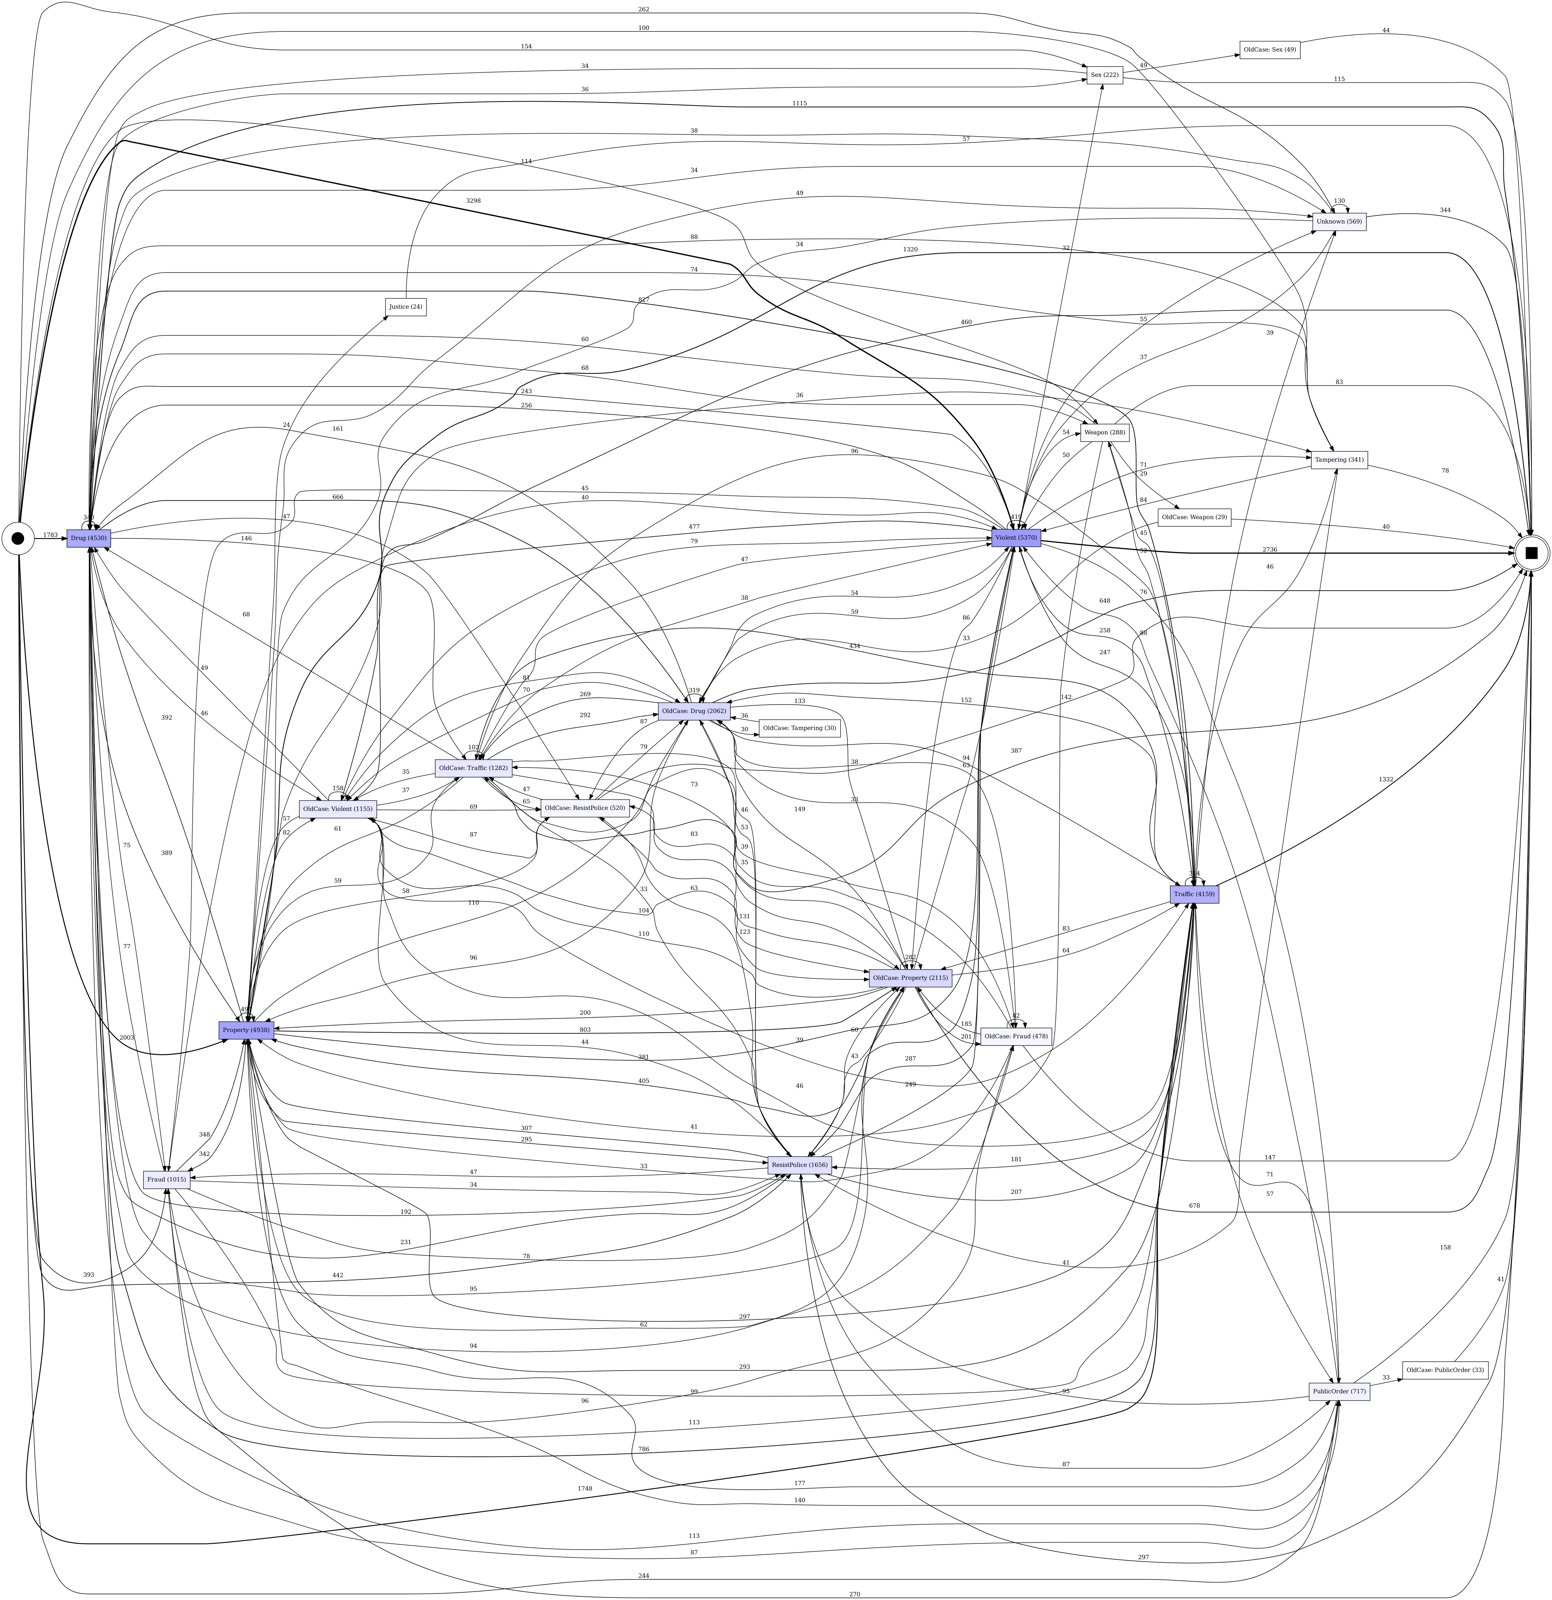

In [21]:
dfg, sa, ea = DFG["x2"]
print("дуг DFG:", len(dfg), "| начальных активностей:", len(sa), "| конечных:", len(ea))
# полный граф (557 дуг) как рисунок нечитаем и весит ~25 МБ, поэтому все его дуги сохраняются таблицей
pd.Series(dfg).rename_axis(["from", "to"]).rename("count").sort_values(ascending=False).to_csv(OUT / "dfg_arcs_x2.csv")
dfg_f, sa_f, ea_f = pm4py.filter_dfg_paths_percentage(dfg, sa, ea, 0.3)
ac_f = {a for k in dfg_f for a in k}
print("в отфильтрованном (30% путей): дуг", len(dfg_f), "| активностей", len(ac_f))
pm4py.save_vis_dfg(dfg_f, sa_f, ea_f, str(FIG / "dfg_frequency_paths30.png"))
show(FIG / "dfg_frequency_paths30.png")

In [22]:
# самые частые дуги DFG
arcs = pd.Series(dfg).sort_values(ascending=False).rename("частота")
arcs.index = [f"{a} → {b}" for a, b in arcs.index]
arcs.head(25).to_frame()

,частота
Drug → Traffic,827
Property → OldCase: Property,803
Traffic → Drug,786
Drug → OldCase: Drug,666
Property → Property,494
Violent → OldCase: Violent,477
Traffic → OldCase: Traffic,434
Violent → Violent,419
Violent → Property,405
Property → Drug,392


### 4.3. DFG — времена

Та же схема, на дугах — медиана времени между событиями. Между заключениями это время от одного ареста
(`in_custody`) до следующего, внутри заключения — секунды (служебный порядок).

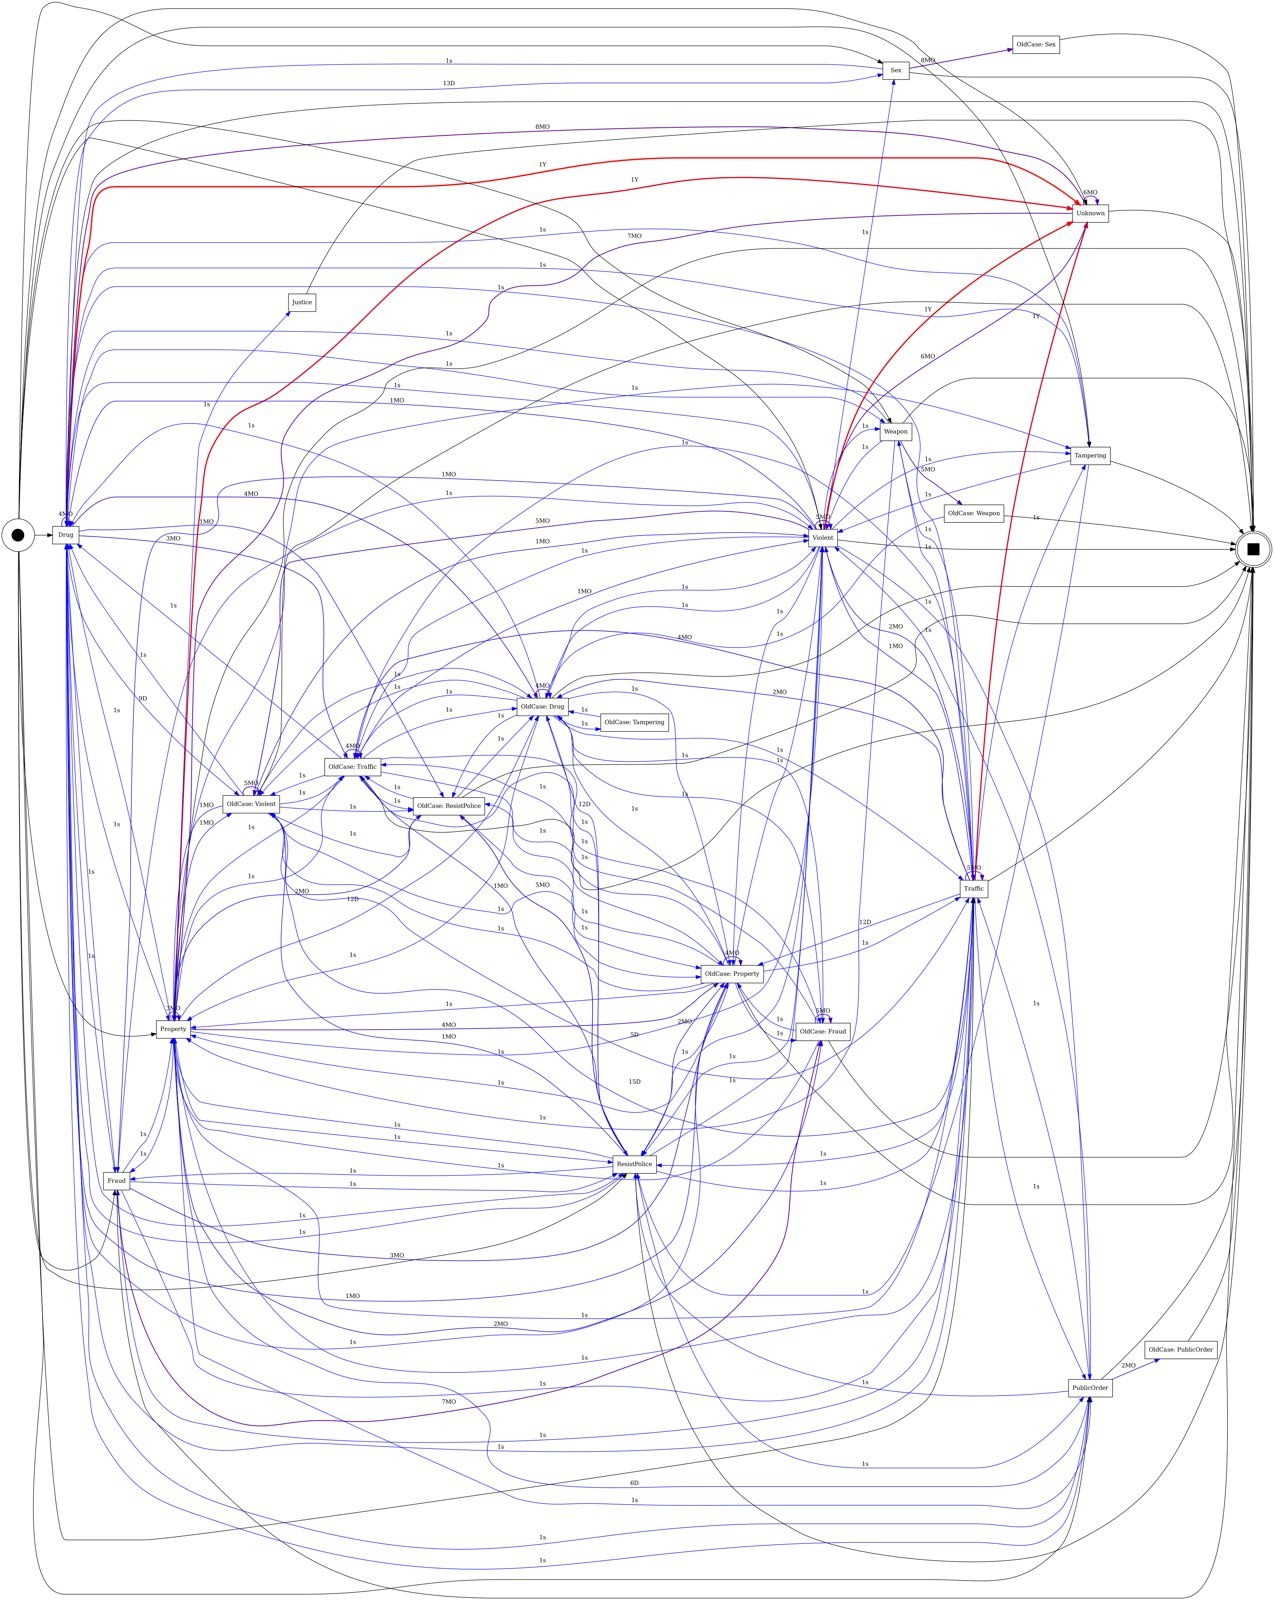

In [23]:
perf, sa_p, ea_p = pm4py.discover_performance_dfg(log, case_id_key="case:concept:name",
                                                 activity_key="concept:name", timestamp_key="time:timestamp")
perf_f = {k: v for k, v in perf.items() if k in dfg_f}
pm4py.save_vis_performance_dfg(perf_f, sa_f, ea_f, str(FIG / "dfg_performance_paths30.png"), aggregation_measure="median")
show(FIG / "dfg_performance_paths30.png")

In [24]:
# медиана дней между заключениями по дугам (только переходы между разными заключениями)
e = ev2.sort_values(["id", "time:timestamp"])
nxt = e.groupby("id").shift(-1)
m = nxt["episode_id"].notna() & (nxt["episode_id"] != e["episode_id"])
gaps = pd.DataFrame({"from": e.loc[m, "concept:name"], "to": nxt.loc[m, "concept:name"],
                     "days": (nxt.loc[m, "in_custody"] - e.loc[m, "in_custody"]).dt.days})
gap_tab = gaps.groupby(["from", "to"])["days"].agg(["size", "median"]).sort_values("size", ascending=False)
gap_tab.head(20)

size  median
from              to                             
Property          OldCase: Property   677   184.0
Drug              OldCase: Drug       567   165.0
Property          Property            494   104.0
Violent           Violent             419   151.0
                  OldCase: Violent    419   181.0
Traffic           OldCase: Traffic    374   149.0
Drug              Drug                340   124.5
OldCase: Drug     OldCase: Drug       319   131.0
Traffic           Traffic             314   151.5
OldCase: Property OldCase: Property   282   137.5
Drug              Property            183   136.0
                  Traffic             169   144.0
Traffic           Drug                165   125.0
Property          Drug                162   124.5
OldCase: Violent  OldCase: Violent    158   160.5
Violent           Property            157   190.0
                  Traffic             149   291.0
Traffic           Violent             147   205.0
Violent           Drug                143   204.0
Traffic           Property            133   109.0

### 4.4. Матрица переходов между шагами

Вероятность следующего состояния по текущему на уровне шагов (как в Этапе 1): переход между шагами
`S_k → S_{k+1}` делится на все пары категорий с весом `1 / (|S_k| · |S_{k+1}|)`, строки нормируются.
Это подготовка к шагу 5 плана (матрица переходов для конкурирующих рисков).

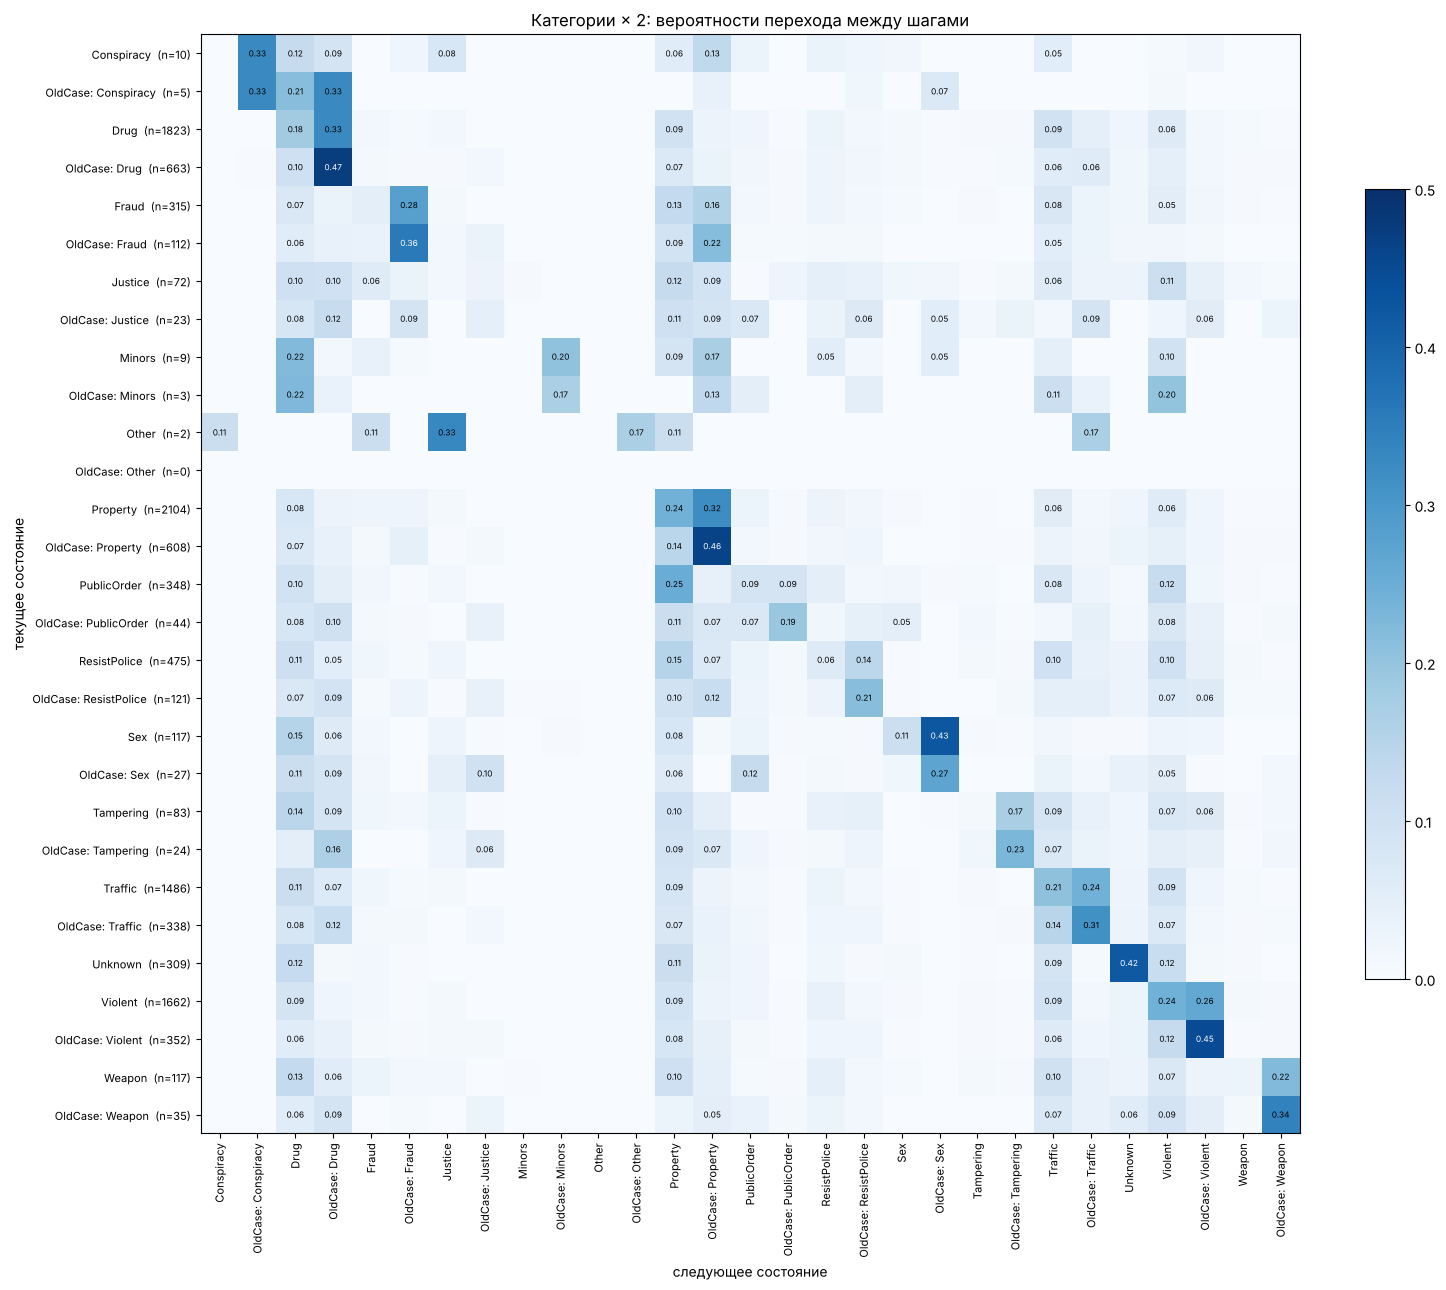

In [25]:
tr2, _, _, _ = step_stats(st2)
w_rows = []
for a, b in zip(tr2["types"], tr2["next_types"]):
    w = 1.0 / (len(a) * len(b))
    for x in a:
        for y in b:
            w_rows.append((x, y, w))
W = pd.DataFrame(w_rows, columns=["from", "to", "w"]).pivot_table(index="from", columns="to", values="w", aggfunc="sum", fill_value=0)
order = sorted(set(W.index) | set(W.columns), key=lambda a: (base_type(a), a.startswith(OLD_PREFIX)))
W = W.reindex(index=order, columns=order, fill_value=0)
P = W.div(W.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
W.round(1).to_csv(OUT / "transition_weighted_counts_x2.csv")
P.round(4).to_csv(OUT / "transition_probs_x2.csv")

fig, ax = plt.subplots(figsize=(15, 13))
im_ = ax.imshow(P.values, cmap="Blues", vmin=0, vmax=max(0.5, P.values.max()))
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=8)
ax.set_yticks(range(len(order)), [f"{a}  (n={W.loc[a].sum():.0f})" for a in order], fontsize=8)
for i in range(len(order)):
    for j in range(len(order)):
        if P.values[i, j] >= 0.05:
            ax.text(j, i, f"{P.values[i, j]:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if P.values[i, j] > 0.35 else "black")
ax.set_xlabel("следующее состояние"); ax.set_ylabel("текущее состояние")
ax.set_title("Категории × 2: вероятности перехода между шагами")
fig.colorbar(im_, ax=ax, fraction=0.03)
fig.tight_layout(); fig.savefig(FIG / "transition_matrix_x2.png", dpi=130); plt.show()

### 4.5. Heuristics Miner

Heuristics Miner оставляет дугу `A → B`, если мера зависимости `(|A>B| − |B>A|) / (|A>B| + |B>A| + 1)` не меньше
порога. В Этапе 1 лучшим был порог 0.9 (fitness ≈ 0.99 на тесте). Строятся эвристическая сеть и сеть Петри.

HM 0.9: мест 54, переходов 328, дуг 661  (21 с)


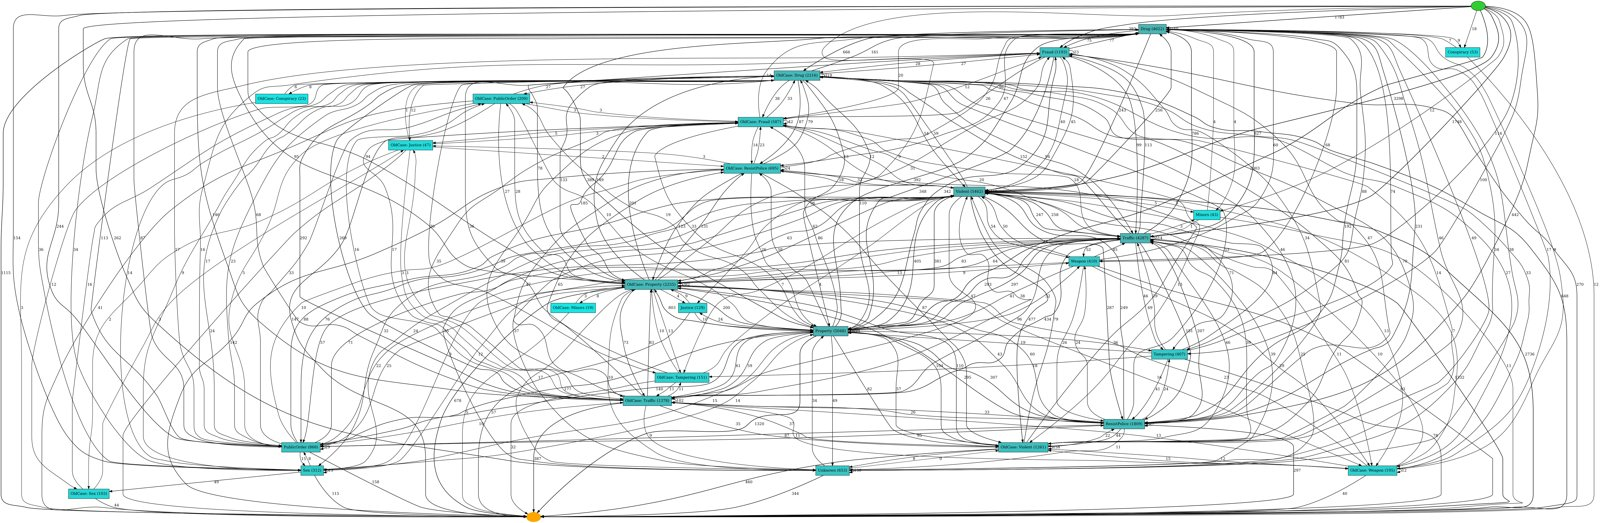

In [26]:
t0 = time.time()
hn = pm4py.discover_heuristics_net(log, dependency_threshold=0.9)
pm4py.save_vis_heuristics_net(hn, str(FIG / "heuristics_net_dep0.9.png"))
net_hm, im_hm, fm_hm = pm4py.discover_petri_net_heuristics(log, dependency_threshold=0.9)
pm4py.save_vis_petri_net(net_hm, im_hm, fm_hm, str(FIG / "petri_HM_dep0.9.png"))
print(f"HM 0.9: мест {len(net_hm.places)}, переходов {len(net_hm.transitions)}, дуг {len(net_hm.arcs)}  ({time.time() - t0:.0f} с)")
show(FIG / "heuristics_net_dep0.9.png")

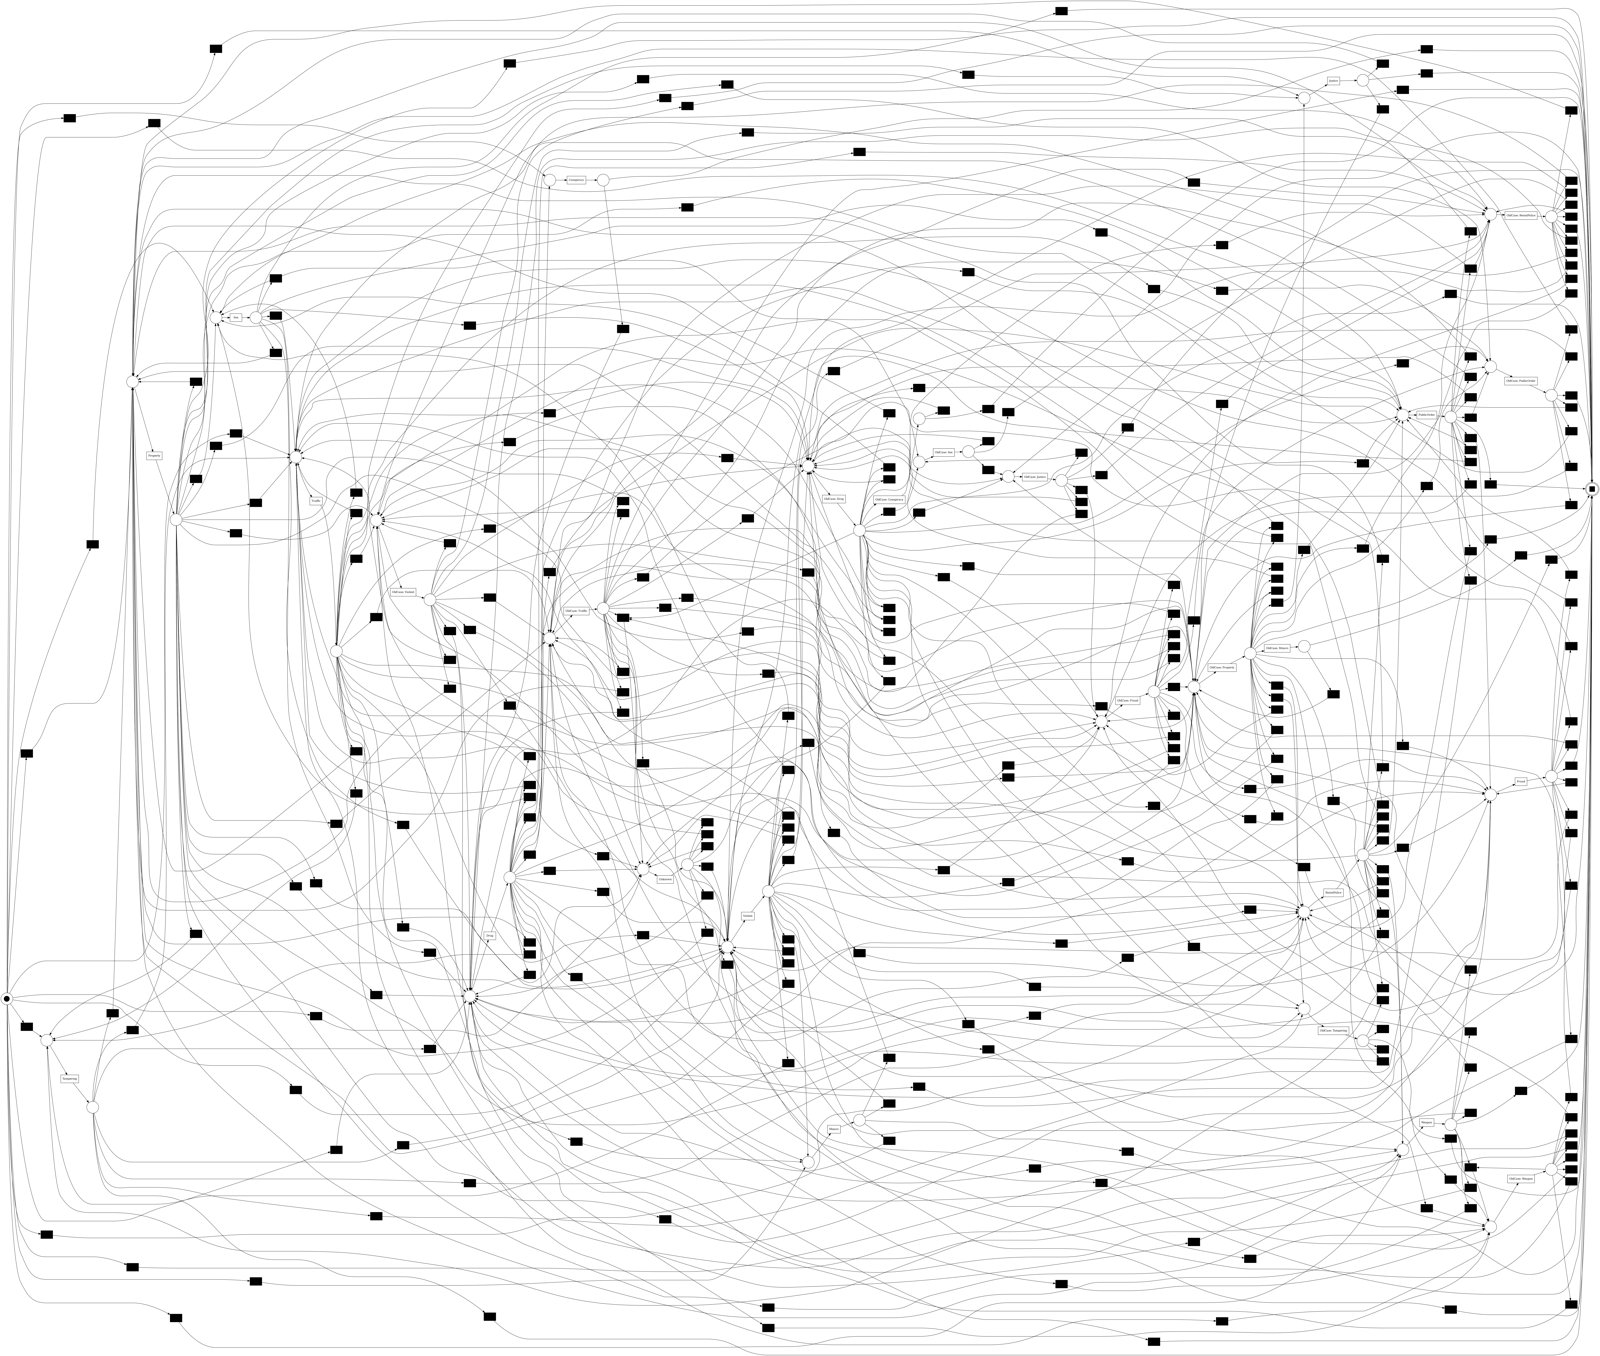

In [27]:
show(FIG / "petri_HM_dep0.9.png")

### 4.6. Inductive Miner

Inductive Miner строит дерево процесса (блочную модель) и из него — сеть Петри, которая гарантированно корректна
(sound). Порог шума 0.2 отбрасывает редкие связи (как в Этапе 1).

IM 0.2: мест 46, переходов 84 (из них скрытых 55)  (2 с)


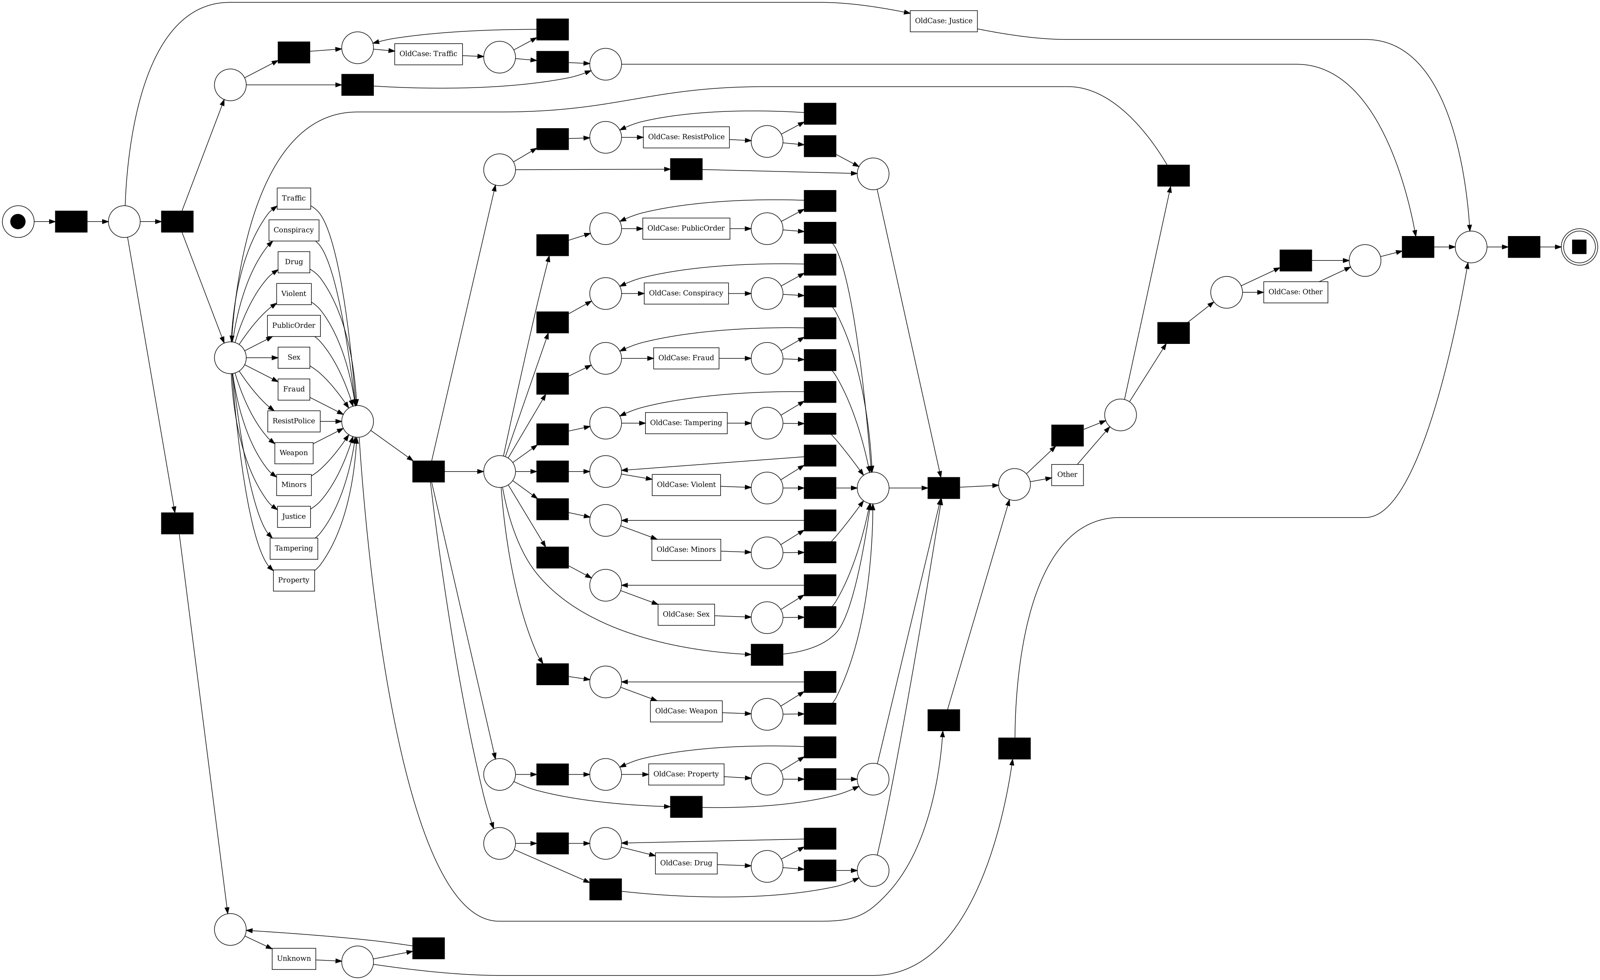

In [28]:
t0 = time.time()
tree = pm4py.discover_process_tree_inductive(log, noise_threshold=0.2)
pm4py.save_vis_process_tree(tree, str(FIG / "process_tree_IM_noise0.2.png"))
net_im, im_im, fm_im = pm4py.convert_to_petri_net(tree)
pm4py.save_vis_petri_net(net_im, im_im, fm_im, str(FIG / "petri_IM_noise0.2.png"))
print(f"IM 0.2: мест {len(net_im.places)}, переходов {len(net_im.transitions)} "
      f"(из них скрытых {sum(t.label is None for t in net_im.transitions)})  ({time.time() - t0:.0f} с)")
show(FIG / "petri_IM_noise0.2.png")

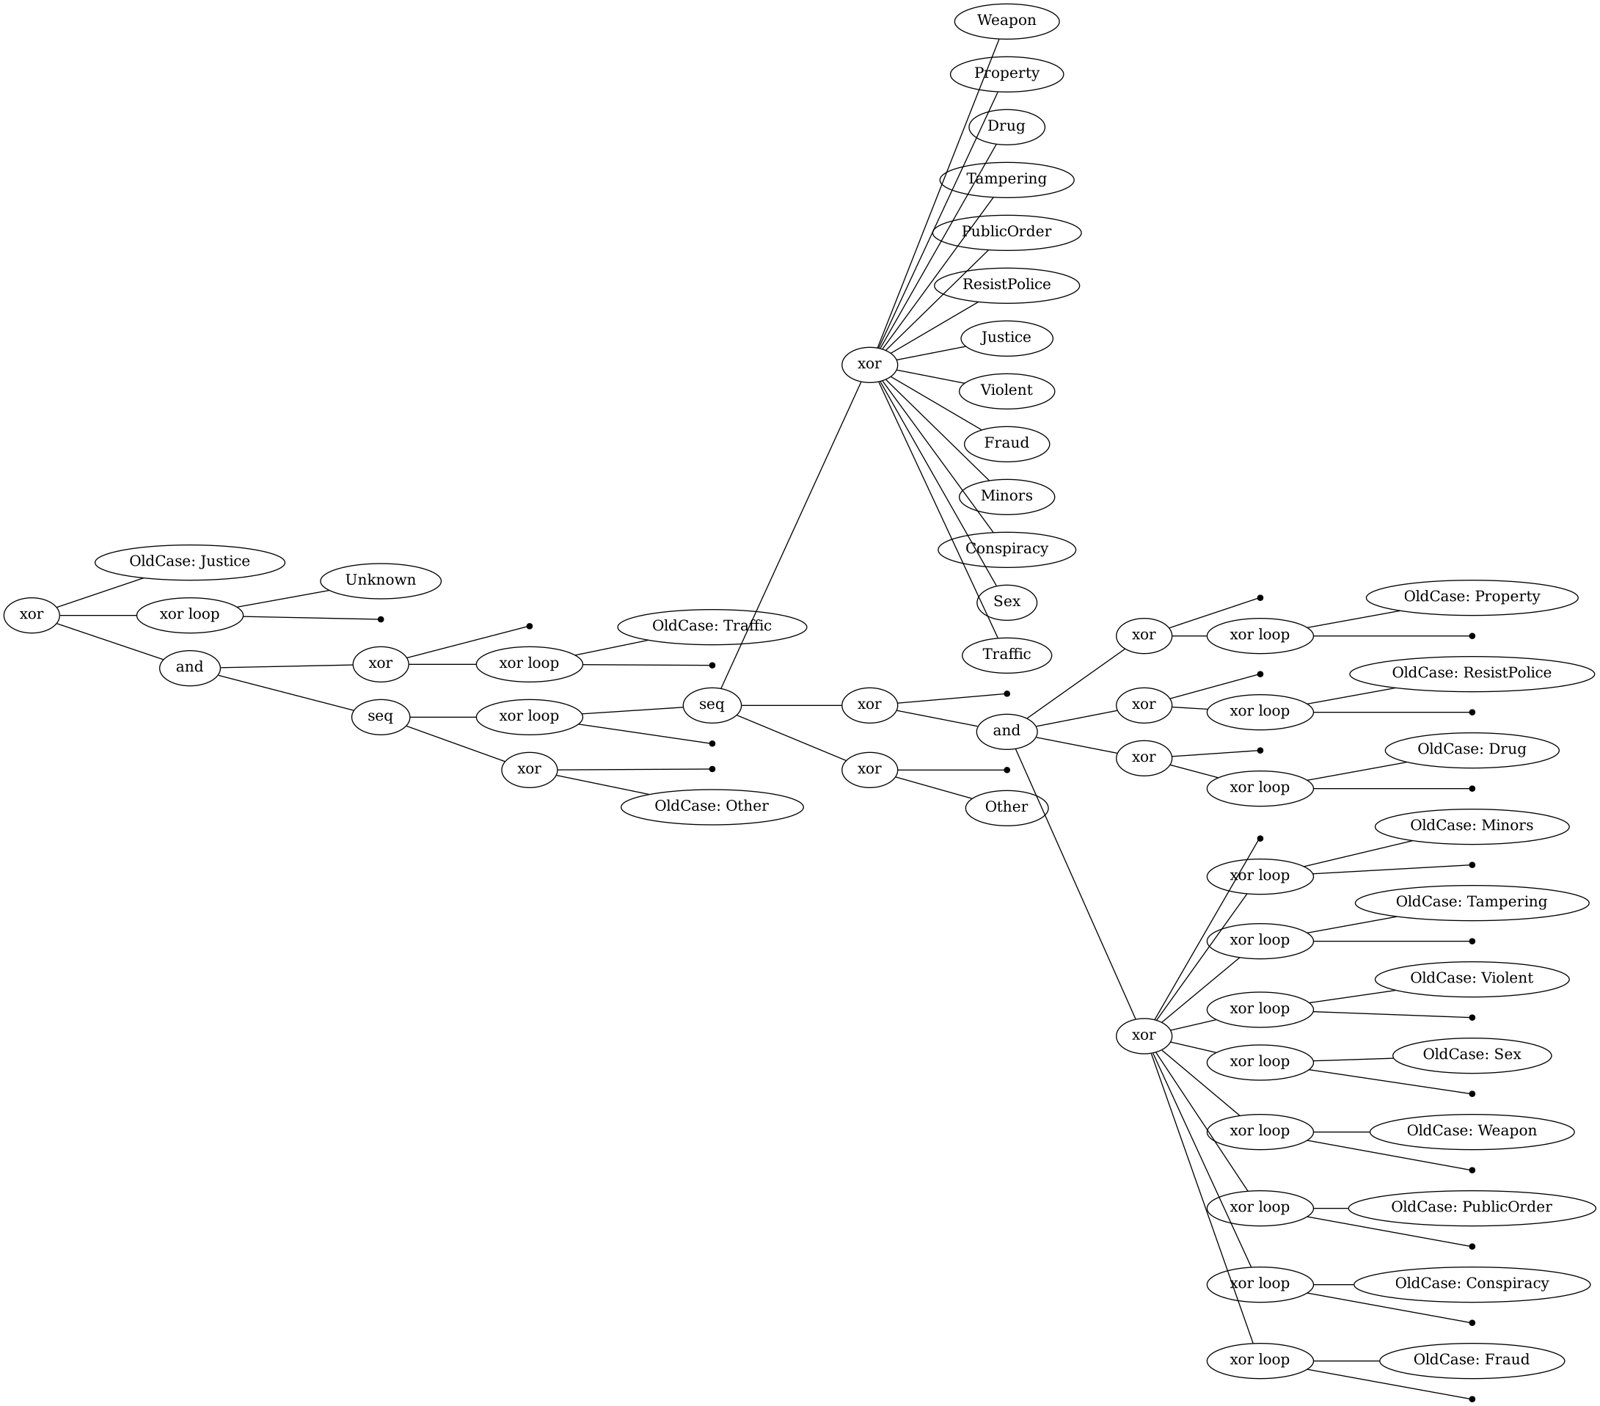

In [29]:
show(FIG / "process_tree_IM_noise0.2.png")

### 4.7. Качество моделей (по флагу `RUN_EVAL`)

Люди делятся на train (80%) и test (20%), seed 42. Модели строятся на train и проверяются на выборке из test
(не больше `EVAL_MAX_CASES` людей): **fitness** (насколько модель воспроизводит трассы) и **precision** (насколько
модель не разрешает лишнего), обе через token-based replay. Выравнивания (alignments) на 30 состояниях считаются
очень долго, поэтому здесь не используются.

Расчёт занимает около 2–3 минут. При `RUN_EVAL = False` показывается сохранённая таблица `out/model_quality_x2.csv`.

In [30]:
QUALITY = OUT / "model_quality_x2.csv"
if RUN_EVAL:
    rng = np.random.default_rng(SEED)
    ids = log["case:concept:name"].unique()
    test_ids = set(rng.choice(ids, size=int(0.2 * len(ids)), replace=False))
    train = log[~log["case:concept:name"].isin(test_ids)]
    test = log[log["case:concept:name"].isin(test_ids)]
    sample = sorted(test_ids)[:EVAL_MAX_CASES]
    test_s = test[test["case:concept:name"].isin(sample)]
    train_s = train[train["case:concept:name"].isin(sorted(set(train["case:concept:name"]))[:EVAL_MAX_CASES])]
    models = {}
    for d in (0.5, 0.9):
        models[f"HM_dep{d}"] = pm4py.discover_petri_net_heuristics(train, dependency_threshold=d)
    for nt in (0.0, 0.2, 0.5):
        models[f"IM_noise{nt}"] = pm4py.discover_petri_net_inductive(train, noise_threshold=nt)
    q = []
    for name, (net, im, fm) in models.items():
        for split, lg in (("train", train_s), ("test", test_s)):
            t0 = time.time()
            fit = pm4py.fitness_token_based_replay(lg, net, im, fm)
            prec = pm4py.precision_token_based_replay(lg, net, im, fm)
            q.append(dict(model=name, split=split, cases=lg["case:concept:name"].nunique(),
                          fitness_tbr=round(fit["log_fitness"], 4),
                          pct_fit_traces=round(fit["percentage_of_fitting_traces"], 2),
                          precision_etc=round(prec, 4),
                          f1=round(2 * fit["log_fitness"] * prec / (fit["log_fitness"] + prec), 4),
                          places=len(net.places), transitions=len(net.transitions),
                          silent=sum(t.label is None for t in net.transitions), sec=round(time.time() - t0)))
            print(q[-1])
    quality = pd.DataFrame(q)
    quality.to_csv(QUALITY, index=False)
else:
    quality = pd.read_csv(QUALITY)
quality

,model,split,cases,fitness_tbr,pct_fit_traces,precision_etc,f1,places,transitions,silent,sec
0,HM_dep0.5,train,2000,0.9409,66.35,0.5976,0.7309,111,408,379,10
1,HM_dep0.5,test,2000,0.9382,65.60,0.6106,0.7398,111,408,379,10
2,HM_dep0.9,train,2000,0.9869,90.80,0.5070,0.6699,53,323,297,9
3,HM_dep0.9,test,2000,0.9856,90.25,0.5250,0.6851,53,323,297,9
4,IM_noise0.0,train,2000,1.0000,100.00,0.3425,0.5103,74,116,87,23
5,IM_noise0.0,test,2000,1.0000,100.00,0.3567,0.5258,74,116,87,23
6,IM_noise0.2,train,2000,0.9961,95.60,0.3461,0.5137,60,96,67,15
7,IM_noise0.2,test,2000,0.9962,95.75,0.3645,0.5338,60,96,67,15
8,IM_noise0.5,train,2000,0.8323,14.05,0.4123,0.5514,75,114,86,15
9,IM_noise0.5,test,2000,0.8318,13.30,0.4339,0.5703,75,114,86,14


## Итоги

Числа ниже — из запуска этого ноутбука 10.10.2026 (могут незначительно отличаться только при другой версии pandas/pm4py).

**Журнал x2.** 10 580 человек, 21 716 заключений (ни одно не убрано), 21 866 шагов, 34 441 событие, **29 состояний**
(15 категорий + 14 `OldCase: X`; `OldCase: Unknown` не встречается: у заключений без найденного обвинения нет номера
дела). Событий на 1 077 больше, чем в варианте «все новые»: в 1 677 смешанных заключениях одна категория может
дать и `X`, и `OldCase: X`. Без приставки `OldCase:` категории каждого заключения совпадают с вариантом «все новые».

**Петли.** Доля переходов между заключениями с тем же набором состояний: все новые 0.443, OldCase 0.214,
без OldCase 0.218, **x2 0.177** — меньше всех. Из 11 266 пар-петель `X → X` варианта «все новые» в x2 настоящими
петлями (снова новое дело той же категории) остались 3 544; 5 813 стали переходом `X → OldCase: X`, ещё 2 696 —
`OldCase: X → OldCase: X` (несколько заключений подряд по одному старому делу; это теперь главный источник петель),
716 — `OldCase: X → X`. В журнале событий доля событий-петель DFG 0.115 против 0.232 / 0.163 / 0.157.

**Цена.** Граф заметно сложнее: 557 дуг DFG против 180–207, 1 093 разных набора состояний шага против 300–342,
3 268 вариантов трасс против 2 398–2 990.

**Матрица переходов.** Самые сильные переходы — повторы по старому делу: `OldCase: Drug → OldCase: Drug` 0.47,
`OldCase: Property →` себя 0.46, `OldCase: Violent →` себя 0.45; затем `X → OldCase: X` (Drug 0.33, Property 0.32,
Violent 0.26, Traffic 0.24); настоящие петли по новым делам — Property 0.24, Violent 0.24, Traffic 0.21, Drug 0.18.

**Модели** (обучение на 80% людей, проверка на выборке 2 000 человек из тестовых 20%, token-based replay):
HM 0.9 — fitness 0.986, precision 0.525; HM 0.5 — 0.938 / 0.611; IM 0.2 — 0.996 / 0.365; IM 0.0 — 1.000 / 0.357.
Для сравнения в варианте OldCase HM 0.9 на тесте давал 0.995 / 0.675. Модели почти так же хорошо воспроизводят
трассы, но точность ниже: при 29 состояниях модель разрешает больше лишних путей. IM строит блок «новые категории в
цикле → необязательные `OldCase: X` параллельно», то есть почти не различает порядок переходов.

## Файлы в `out/`

| Файл | Что внутри |
|---|---|
| `event_log_x2.csv` / `.xlsx` | журнал событий варианта «категории × 2» для PM4Py |
| `steps_x2.csv` | одна строка на шаг (заключение) |
| `log_summary_4variants.csv` | сводка по четырём вариантам |
| `stats_x2_vs_variants.xlsx` | статистика и сравнение вариантов (шаг 3) |
| `transition_weighted_counts_x2.csv`, `transition_probs_x2.csv` | матрица переходов между шагами |
| `dfg_arcs_x2.csv` | все дуги полного DFG с частотами |
| `model_quality_x2.csv` | fitness / precision моделей |
| `figures/` | DFG (частоты, времена), матрица переходов, эвристическая сеть, сети Петри HM и IM, дерево процесса |

## Дальнейший план работ

5. Проверка качества моделей (fitness / precision) и выбор модели для варианта x2; сравнение с моделями других вариантов.
6. Матрица переходов → конкурирующие риски с цензурированием (следующее состояние и время до него).
7. Перенос подхода на Instacart (состояние = сегмент покупателя).